# Who should be sent for angiography? A decision tree on the UCI Heart Disease data

**Approach (option 1 of the brief):** train and evaluate a decision-tree classifier.

**Question:** a patient comes in with chest symptoms. Should the doctor send them for angiography, the invasive test that confirms heart disease?

- **Target:** `disease` = 1 if angiography shows heart disease (at least one major vessel narrowed by more than 50%), else 0.
- **Decision:** send the patient for angiography or not.
- **Metrics:** accuracy, recall (share of sick patients we catch) and specificity (share of healthy patients we correctly leave out) for the classifier, and **average cost per patient** for the decision.

**Plan of the notebook**

1. Data and preprocessing (sections 1–2)
2. Train / test split and baseline (3)
3. How the tree splits, how deep it grows, the final tree (4–6)
4. Test results, used once (7)
5. From prediction to decision: costs and the Bayes rule (8)
6. Robustness checks that answer the obvious questions (9): tuning for cost, information available before the decision, stability across splits, test-set uncertainty
7. Summary, recommendation and limitations (10–11)

Every figure is saved to `figures/` so it can go straight onto the slides.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 220, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 120)

## 1. The dataset

Cleveland Clinic heart disease data from the UCI Machine Learning Repository:
Janosi, A., Steinbrunn, W., Pfisterer, M., and Detrano, R. (1989). *Heart Disease* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C52P4X

We use the processed Cleveland file (`processed.cleveland.data`): 303 patients, 13 input variables, 1 target. Missing values are written as `?`.

In [2]:
columns = ["age", "sex", "chest_pain", "rest_bp", "cholesterol", "high_fasting_sugar", "rest_ecg",
           "max_heart_rate", "exercise_angina", "st_depression", "st_slope", "n_vessels", "thal", "num"]
raw = pd.read_csv("data/processed.cleveland.data", header=None, names=columns, na_values="?")
print(raw.shape)
raw.head()

(303, 14)


,age,sex,chest_pain,rest_bp,cholesterol,high_fasting_sugar,rest_ecg,max_heart_rate,exercise_angina,st_depression,st_slope,n_vessels,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


The column **"obtained from"** matters for the decision. A rule can only use what the doctor knows *before* choosing (Lecture 1: information available when the action is chosen).

- Most inputs come from the consultation, a blood test, a resting ECG, or an exercise ECG (treadmill test). These are routine and non-invasive.
- Two inputs come from **extra imaging tests**: `thal` (a thallium nuclear stress scan) and `n_vessels` (number of vessels seen on fluoroscopy). The UCI documentation does not say exactly when these were done, and fluoroscopy can be part of the catheterisation itself. Section 9.2 checks what happens without them.

In [3]:
descriptions = {
    "age": "Age in years",
    "sex": "1 = male, 0 = female",
    "chest_pain": "Chest pain type: typical angina, atypical angina, non-anginal, asymptomatic",
    "rest_bp": "Resting blood pressure (mm Hg)",
    "cholesterol": "Serum cholesterol (mg/dl)",
    "high_fasting_sugar": "Fasting blood sugar > 120 mg/dl (1 = yes)",
    "rest_ecg": "Resting ECG: normal, ST-T abnormality, LV hypertrophy",
    "max_heart_rate": "Maximum heart rate during exercise test",
    "exercise_angina": "Chest pain caused by exercise (1 = yes)",
    "st_depression": "ST depression on ECG during exercise vs rest",
    "st_slope": "Slope of peak exercise ST segment: up, flat, down",
    "n_vessels": "Number of major vessels coloured by fluoroscopy (0-3)",
    "thal": "Thallium stress test: normal, fixed defect, reversible defect",
    "num": "Diagnosis 0-4 (0 = no disease) -> our target",
}
source = {
    "age": "consultation", "sex": "consultation", "chest_pain": "consultation",
    "rest_bp": "consultation", "cholesterol": "blood test", "high_fasting_sugar": "blood test",
    "rest_ecg": "resting ECG", "max_heart_rate": "exercise ECG", "exercise_angina": "exercise ECG",
    "st_depression": "exercise ECG", "st_slope": "exercise ECG",
    "n_vessels": "EXTRA TEST: fluoroscopy", "thal": "EXTRA TEST: thallium scan", "num": "angiography (target)",
}
variables = pd.DataFrame(index=columns, data={
    "description": [descriptions[c] for c in columns],
    "type": ["numeric", "binary", "categorical", "numeric", "numeric", "binary", "categorical",
             "numeric", "binary", "numeric", "categorical", "numeric", "categorical", "target"],
    "obtained from": [source[c] for c in columns],
    "missing": raw.isna().sum(),
})
variables

,description,type,obtained from,missing
age,Age in years,numeric,consultation,0
sex,"1 = male, 0 = female",binary,consultation,0
chest_pain,"Chest pain type: typical angina, atypical angi...",categorical,consultation,0
rest_bp,Resting blood pressure (mm Hg),numeric,consultation,0
cholesterol,Serum cholesterol (mg/dl),numeric,blood test,0
high_fasting_sugar,Fasting blood sugar > 120 mg/dl (1 = yes),binary,blood test,0
rest_ecg,"Resting ECG: normal, ST-T abnormality, LV hype...",categorical,resting ECG,0
max_heart_rate,Maximum heart rate during exercise test,numeric,exercise ECG,0
exercise_angina,Chest pain caused by exercise (1 = yes),binary,exercise ECG,0
st_depression,ST depression on ECG during exercise vs rest,numeric,exercise ECG,0


**Missing values:** only 6 of 303 patients have a missing value (4 in `n_vessels`, 2 in `thal`). That is 2% of the rows, so we drop them. Dropping rows does not learn anything from the data, so it cannot leak test information.

**Target:** the original `num` goes from 0 to 4. As in most studies on this data, we turn it into yes/no: `disease = 1` if `num > 0`.

In [4]:
df = raw.dropna().copy()
df["disease"] = (df["num"] > 0).astype(int)
df = df.drop(columns="num")
print(f"Rows after dropping missing values: {len(df)} (dropped {len(raw) - len(df)})")

counts = df["disease"].value_counts().sort_index()
target_table = pd.DataFrame({"patients": counts, "share": (counts / len(df)).round(3)},
                            index=pd.Index([0, 1], name="disease"))
target_table.index = ["0 = no disease", "1 = disease"]
target_table

Rows after dropping missing values: 297 (dropped 6)


,patients,share
0 = no disease,160,0.539
1 = disease,137,0.461


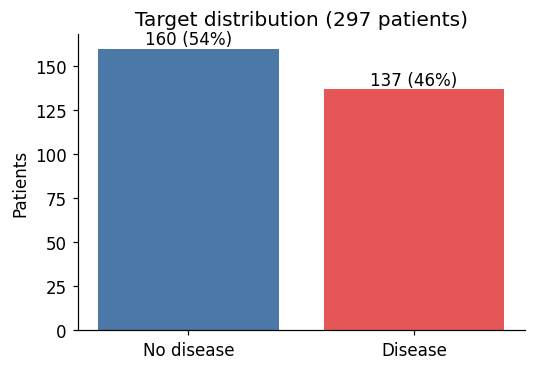

In [5]:
fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar(["No disease", "Disease"], counts.values, color=["#4C78A8", "#E45756"])
ax.bar_label(bars, labels=[f"{c} ({c / len(df):.0%})" for c in counts.values])
ax.set_ylabel("Patients")
ax.set_title("Target distribution (297 patients)")
fig.tight_layout()
fig.savefig("figures/01_target_distribution.png")
plt.show()

**Who are these patients?** A few descriptive numbers, and the share of sick patients for each type of chest pain.

In [6]:
print(f"Men: {df['sex'].mean():.0%}. Age: {df['age'].min():.0f} to {df['age'].max():.0f} years, mean {df['age'].mean():.1f}.")
print("Original diagnosis num (0 = no disease, 1-4 = disease):", raw.dropna()["num"].value_counts().sort_index().to_dict())
pain = df.groupby("chest_pain")["disease"].agg(patients="size", share_with_disease="mean").round(2)
pain.index = [{1: "typical angina", 2: "atypical angina", 3: "non-anginal", 4: "asymptomatic"}[int(k)] for k in pain.index]
pain

Men: 68%. Age: 29 to 77 years, mean 54.5.
Original diagnosis num (0 = no disease, 1-4 = disease): {0: 160, 1: 54, 2: 35, 3: 35, 4: 13}


,patients,share_with_disease
typical angina,23,0.30
atypical angina,49,0.18
non-anginal,83,0.22
asymptomatic,142,0.73


**A surprising result, and what it tells us about the data.** Patients with *asymptomatic* chest pain are the most often sick (73%), more than patients with typical angina (30%). This is because of **how the patients were selected**: the target comes from angiography, so **every patient in the data was already sent for angiography**. A patient without chest pain was only sent if something else looked worrying (for example an abnormal exercise test), so this group is already high-risk.

Consequence for our decision: the tree learns the risk of disease **among patients a doctor already found worrying enough to test**. Using it on all patients with chest symptoms would be an extrapolation. We keep this in mind in the recommendation and the limitations.

## 2. Preprocessing

Four variables are categories stored as numbers (for example `thal` = 3, 6 or 7). A tree would treat them as ordered numbers, which makes no sense here. We **one-hot encode** them into yes/no columns with readable names, so a split reads like "thal = normal?".

**No leakage.** The brief asks to fit preprocessing inside each training split. Here the preprocessing learns nothing from the data: the list of categories comes from the data dictionary, and trees need no scaling. So doing it once before the split gives exactly the same result as doing it inside every fold.

In [7]:
category_names = {
    "chest_pain": {1: "typical_angina", 2: "atypical_angina", 3: "non_anginal", 4: "asymptomatic"},
    "rest_ecg": {0: "normal", 1: "st_t_abnormal", 2: "lv_hypertrophy"},
    "st_slope": {1: "up", 2: "flat", 3: "down"},
    "thal": {3: "normal", 6: "fixed_defect", 7: "reversible_defect"},
}
X = df.drop(columns="disease").copy()
for col, names in category_names.items():
    X[col] = pd.Categorical(X[col].map(names), categories=list(names.values()))
X = pd.get_dummies(X, columns=list(category_names), dtype=int)
y = df["disease"]
print(X.shape)
list(X.columns)

(297, 22)


['age',
 'sex',
 'rest_bp',
 'cholesterol',
 'high_fasting_sugar',
 'max_heart_rate',
 'exercise_angina',
 'st_depression',
 'n_vessels',
 'chest_pain_typical_angina',
 'chest_pain_atypical_angina',
 'chest_pain_non_anginal',
 'chest_pain_asymptomatic',
 'rest_ecg_normal',
 'rest_ecg_st_t_abnormal',
 'rest_ecg_lv_hypertrophy',
 'st_slope_up',
 'st_slope_flat',
 'st_slope_down',
 'thal_normal',
 'thal_fixed_defect',
 'thal_reversible_defect']

## 3. Train / test split and baseline

- **Test set (25%, 75 patients):** set aside now and used once, at the very end.
- **Training set (75%, 222 patients):** used to fit and tune the tree. We tune with **5-fold cross-validation** inside the training set, because 222 patients is too few for a separate validation set.
- Both splits are **stratified**, so they keep the same share of sick patients.

**Baseline:** always predict the most common class ("no disease"). A useful model must beat it.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
print(f"train: {len(X_train)} patients, {y_train.mean():.0%} with disease")
print(f"test:  {len(X_test)} patients, {y_test.mean():.0%} with disease")

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
baseline_acc = accuracy_score(y_test, baseline.predict(X_test))
print(f"Baseline test accuracy (always 'no disease'): {baseline_acc:.3f}, recall: 0.000")

train: 222 patients, 46% with disease
test:  75 patients, 47% with disease
Baseline test accuracy (always 'no disease'): 0.533, recall: 0.000


## 4. How a tree chooses a split: Gini impurity

For a group of patients where a fraction $q$ is sick, the Gini impurity is $G(q) = 2q(1-q)$. It is 0 for a pure group and 0.5 for a 50/50 mix.
A split is scored by the drop from the parent's impurity to the **size-weighted** impurity of the two children. The tree tries every variable and every cut point, and keeps the biggest drop.

Below we check this by hand for the first split the tree picks on our training set.

In [9]:
def gini(q):
    return 2 * q * (1 - q)

stump = DecisionTreeClassifier(max_depth=1, random_state=SEED).fit(X_train, y_train)
feature = X_train.columns[stump.tree_.feature[0]]
threshold = stump.tree_.threshold[0]
left = X_train[feature] <= threshold

rows = []
for name, mask in [("Parent (all training)", np.ones(len(y_train), bool)),
                   (f"Left: {feature} <= {threshold:g}", left.values),
                   (f"Right: {feature} > {threshold:g}", ~left.values)]:
    n, sick = mask.sum(), y_train[mask].sum()
    rows.append({"group": name, "sick / total": f"{sick} / {n}", "q": round(sick / n, 3), "G(q)": round(gini(sick / n), 3)})
gini_table = pd.DataFrame(rows)

n_left, n_right, n = left.sum(), (~left).sum(), len(left)
weighted = n_left / n * gini_table.loc[1, "G(q)"] + n_right / n * gini_table.loc[2, "G(q)"]
print(gini_table.to_string(index=False))
print(f"\nWeighted child impurity = {n_left}/{n} x {gini_table.loc[1, 'G(q)']} + {n_right}/{n} x {gini_table.loc[2, 'G(q)']} = {weighted:.3f}")
print(f"Decrease = {gini_table.loc[0, 'G(q)']} - {weighted:.3f} = {gini_table.loc[0, 'G(q)'] - weighted:.3f}")

                               group sick / total     q  G(q)
               Parent (all training)    102 / 222 0.459 0.497
Left: chest_pain_asymptomatic <= 0.5     24 / 114 0.211 0.332
Right: chest_pain_asymptomatic > 0.5     78 / 108 0.722 0.401

Weighted child impurity = 114/222 x 0.332 + 108/222 x 0.401 = 0.366
Decrease = 0.497 - 0.366 = 0.131


## 5. Tuning: how deep should the tree grow?

A deeper tree fits the training data better but can **overfit**: it learns noise that does not carry over to new patients. We try:

- `max_depth` from 1 to 10: from a single question (a stump) to a tree deep enough to almost memorise 222 patients,
- `min_samples_leaf` in {1, 5, 10, 20}: from no limit to about 10% of the training set per leaf. Larger leaves give more reliable leaf probabilities, which we need for the decision in section 8 (Lecture 3: small leaves make probability estimates unstable),

and keep the pair with the best **5-fold cross-validated accuracy** on the training set. If two settings tie, the shallower one wins, because it comes first in the grid. Section 9.1 repeats the tuning with the decision cost instead of accuracy.

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
param_grid = {"max_depth": list(range(1, 11)), "min_samples_leaf": [1, 5, 10, 20]}
search = GridSearchCV(DecisionTreeClassifier(random_state=SEED), param_grid, cv=cv,
                      scoring="accuracy", return_train_score=True)
search.fit(X_train, y_train)

results = pd.DataFrame(search.cv_results_)
best_depth = search.best_params_["max_depth"]
best_leaf = search.best_params_["min_samples_leaf"]
print(f"Best: max_depth = {best_depth}, min_samples_leaf = {best_leaf}, CV accuracy = {search.best_score_:.3f}")

cv_table = results.pivot(index="param_max_depth", columns="param_min_samples_leaf", values="mean_test_score").round(3)
cv_table.index.name, cv_table.columns.name = "max_depth", "min_samples_leaf"
cv_table

Best: max_depth = 4, min_samples_leaf = 10, CV accuracy = 0.824


min_samples_leaf,1,5,10,20
max_depth,,,,
1,0.716,0.716,0.716,0.716
2,0.766,0.761,0.761,0.761
3,0.815,0.797,0.820,0.775
4,0.815,0.784,0.824,0.775
5,0.797,0.766,0.820,0.775
6,0.802,0.775,0.820,0.775
7,0.784,0.775,0.820,0.775
8,0.784,0.775,0.820,0.775
9,0.784,0.775,0.820,0.775


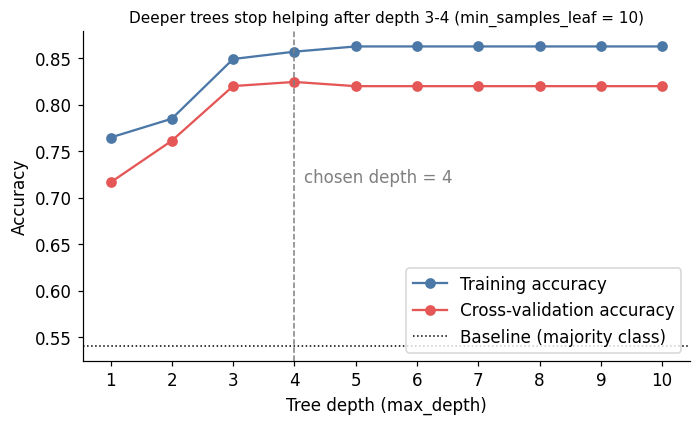

In [11]:
curve = results[results["param_min_samples_leaf"] == best_leaf].sort_values("param_max_depth")
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(curve["param_max_depth"], curve["mean_train_score"], "o-", color="#4C78A8", label="Training accuracy")
ax.plot(curve["param_max_depth"], curve["mean_test_score"], "o-", color="#E45756", label="Cross-validation accuracy")
ax.axvline(best_depth, color="grey", ls="--", lw=1)
ax.annotate(f"chosen depth = {best_depth}", (best_depth, curve["mean_test_score"].min()),
            xytext=(6, 0), textcoords="offset points", color="grey")
ax.axhline(y_train.value_counts(normalize=True).max(), color="black", ls=":", lw=1, label="Baseline (majority class)")
ax.set_xlabel("Tree depth (max_depth)")
ax.set_ylabel("Accuracy")
ax.set_title(f"Deeper trees stop helping after depth 3-4 (min_samples_leaf = {best_leaf})", fontsize=10)
ax.set_xticks(range(1, 11))
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig("figures/02_depth_tuning.png")
plt.show()

## 6. The final tree

`GridSearchCV` refits the chosen tree on the whole training set. We freeze it now, before looking at the test set.

Final decision tree: depth 4, 12 leaves


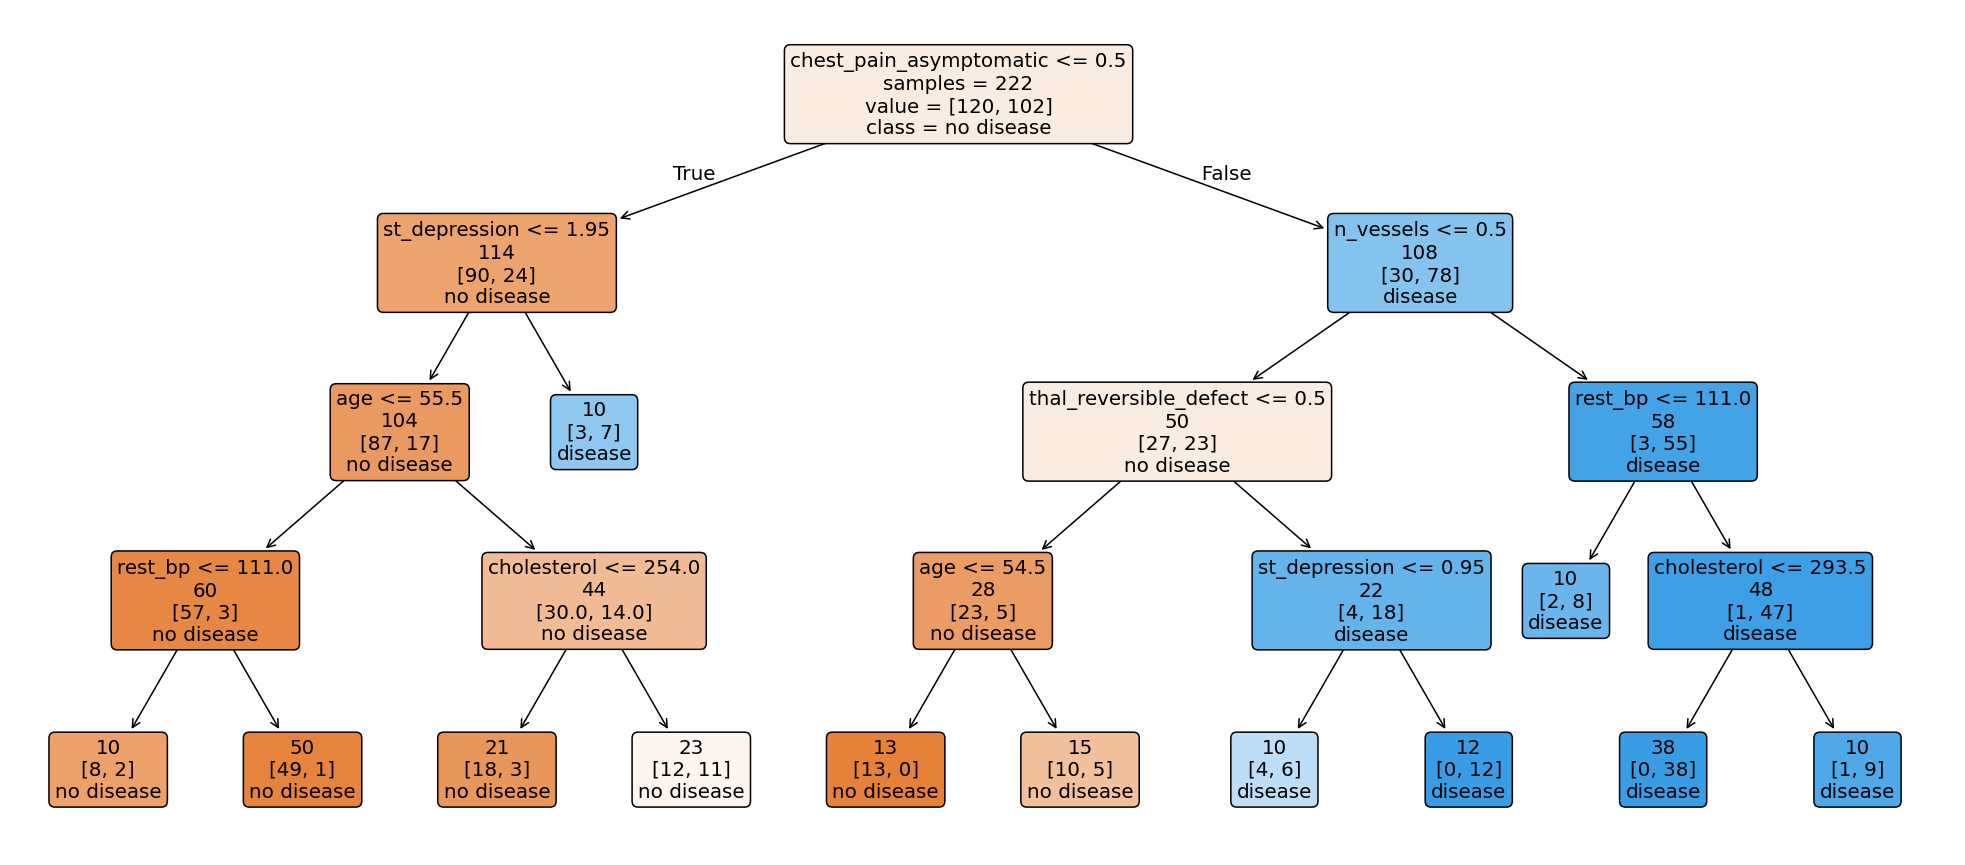

In [12]:
tree = search.best_estimator_
fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(tree, feature_names=list(X.columns), class_names=["no disease", "disease"],
          filled=True, rounded=True, impurity=False, label="root", fontsize=13, ax=ax)
print(f"Final decision tree: depth {tree.get_depth()}, {tree.get_n_leaves()} leaves")
fig.tight_layout()
fig.savefig("figures/03_final_tree.png", bbox_inches="tight", pad_inches=0.05)
plt.show()

In [13]:
print(export_text(tree, feature_names=list(X.columns), show_weights=True))

|--- chest_pain_asymptomatic <= 0.50
|   |--- st_depression <= 1.95
|   |   |--- age <= 55.50
|   |   |   |--- rest_bp <= 111.00
|   |   |   |   |--- weights: [8.00, 2.00] class: 0
|   |   |   |--- rest_bp >  111.00
|   |   |   |   |--- weights: [49.00, 1.00] class: 0
|   |   |--- age >  55.50
|   |   |   |--- cholesterol <= 254.00
|   |   |   |   |--- weights: [18.00, 3.00] class: 0
|   |   |   |--- cholesterol >  254.00
|   |   |   |   |--- weights: [12.00, 11.00] class: 0
|   |--- st_depression >  1.95
|   |   |--- weights: [3.00, 7.00] class: 1
|--- chest_pain_asymptomatic >  0.50
|   |--- n_vessels <= 0.50
|   |   |--- thal_reversible_defect <= 0.50
|   |   |   |--- age <= 54.50
|   |   |   |   |--- weights: [13.00, 0.00] class: 0
|   |   |   |--- age >  54.50
|   |   |   |   |--- weights: [10.00, 5.00] class: 0
|   |   |--- thal_reversible_defect >  0.50
|   |   |   |--- st_depression <= 0.95
|   |   |   |   |--- weights: [4.00, 6.00] class: 1
|   |   |   |--- st_depression >  0.

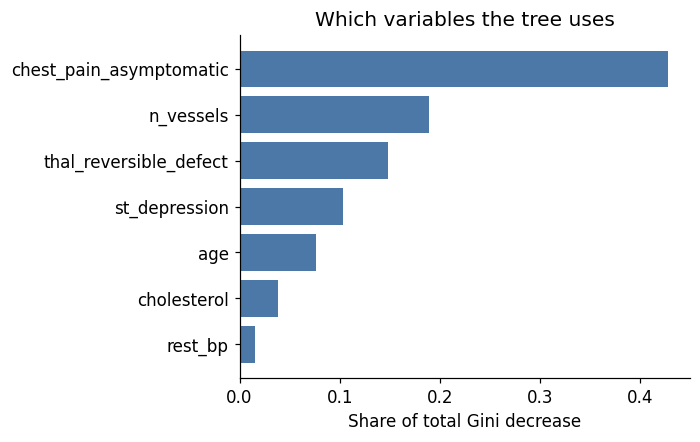

chest_pain_asymptomatic    0.428
n_vessels                  0.189
thal_reversible_defect     0.149
st_depression              0.103
age                        0.077
cholesterol                0.039
rest_bp                    0.016
dtype: float64

In [14]:
importance = pd.Series(tree.feature_importances_, index=X.columns).sort_values()
importance = importance[importance > 0]
fig, ax = plt.subplots(figsize=(6.5, 0.45 * len(importance) + 1))
ax.barh(importance.index, importance.values, color="#4C78A8")
ax.set_xlabel("Share of total Gini decrease")
ax.set_title("Which variables the tree uses")
fig.tight_layout()
fig.savefig("figures/04_feature_importance.png")
plt.show()
importance.sort_values(ascending=False).round(3)

## 7. Test results (used once)

The tree was chosen in section 5 without looking at the test set. We also show the **stump** (the depth-1 tree from section 4) as a reference point: it tells us how much the extra questions add. The stump is not a candidate we pick from on the test set.

- **Recall** = share of sick patients the model flags.
- **Specificity** = share of healthy patients the model leaves out.

In [15]:
def scores(name, y_true, y_hat):
    tn, fp, fn, tp = confusion_matrix(y_true, y_hat, labels=[0, 1]).ravel()
    return {"model": name, "test accuracy": (tp + tn) / len(y_true),
            "recall": tp / (tp + fn), "specificity": tn / (tn + fp)}

y_pred = tree.predict(X_test)
test_table = pd.DataFrame([
    scores("Baseline (always 'no disease')", y_test, baseline.predict(X_test)),
    scores("Stump (1 question, reference)", y_test, stump.predict(X_test)),
    scores(f"Decision tree (depth {tree.get_depth()})", y_test, y_pred),
]).round(3)
test_table

,model,test accuracy,recall,specificity
0,Baseline (always 'no disease'),0.533,0.000,1.000
1,"Stump (1 question, reference)",0.747,0.714,0.775
2,Decision tree (depth 4),0.773,0.686,0.850


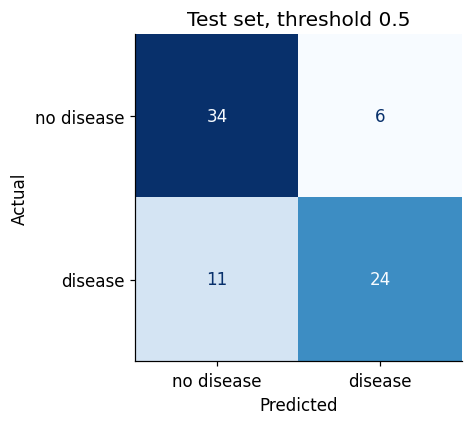

In [16]:
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["no disease", "disease"]).plot(
    ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Test set, threshold 0.5")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
fig.tight_layout()
fig.savefig("figures/05_confusion_matrix.png")
plt.show()

## 8. From prediction to decision: the cost of each mistake

The diagnosis in this dataset comes from **angiography**: an invasive, costly test. The real decision is: **should this patient be sent for angiography?**

Accuracy counts every mistake the same. For the doctor they are not the same. We measure costs in units of "one angiography":

| Loss $L(a, Y)$ | healthy ($Y=0$) | sick ($Y=1$) |
|---|---|---|
| do not send ($a=0$) | 0 | $c$ (missed disease) |
| send for angiography ($a=1$) | 1 | 1 |

Each leaf of the tree gives a probability $\hat p(x)$ = share of sick training patients in that leaf. The expected loss is
$\hat\rho(0 \mid x) = c\,\hat p(x)$ if we do not send, and $\hat\rho(1 \mid x) = 1$ if we send. So the Bayes rule is to **send when $\hat p(x) > 1/c$**, not when $\hat p(x) > 0.5$.

The threshold $1/c$ comes from the loss table, not from the data, so it is **not tuned on the test set**. The tree stays frozen; only the threshold changes with $c$.

**Example:** a missed sick patient costs $c = 3$ angiographies, so we send when $\hat p(x) > 1/3$.

In [17]:
def average_cost(send, y_true, c):
    send, y_true = np.asarray(send), np.asarray(y_true)
    return np.mean(np.where(send == 1, 1, c * y_true))

def policy_rows(p, y_true, c):
    policies = {
        "Send nobody": np.zeros(len(y_true), int),
        "Send everybody": np.ones(len(y_true), int),
        "Tree, send if p > 0.5": (p > 0.5).astype(int),
        f"Tree, send if p > 1/{c} (cost rule)": (p > 1 / c).astype(int),
    }
    return pd.DataFrame([{
        "policy": name,
        "patients sent": int(send.sum()),
        "sick patients missed": int(((send == 0) & (np.asarray(y_true) == 1)).sum()),
        "average cost per patient": round(average_cost(send, y_true, c), 3),
    } for name, send in policies.items()])

p_test = tree.predict_proba(X_test)[:, 1]
print(f"Test set: {len(y_test)} patients, {y_test.sum()} sick. Missed patient cost c = 3.")
policy_table = policy_rows(p_test, y_test, c=3)
policy_table

Test set: 75 patients, 35 sick. Missed patient cost c = 3.


,policy,patients sent,sick patients missed,average cost per patient
0,Send nobody,0,35,1.400
1,Send everybody,75,0,1.000
2,"Tree, send if p > 0.5",30,11,0.840
3,"Tree, send if p > 1/3 (cost rule)",34,10,0.853


At $c = 3$ the 0.5 threshold does very slightly better than the $1/3$ rule on this test set (0.840 vs 0.853). The difference is **one patient out of 75**. The $1/c$ rule is optimal *in expectation* when the leaf probabilities are right; one small test set will not always show it.

**How much does the answer depend on $c$?** We do not know the true cost of a missed patient, so we repeat the comparison for several values of $c$.

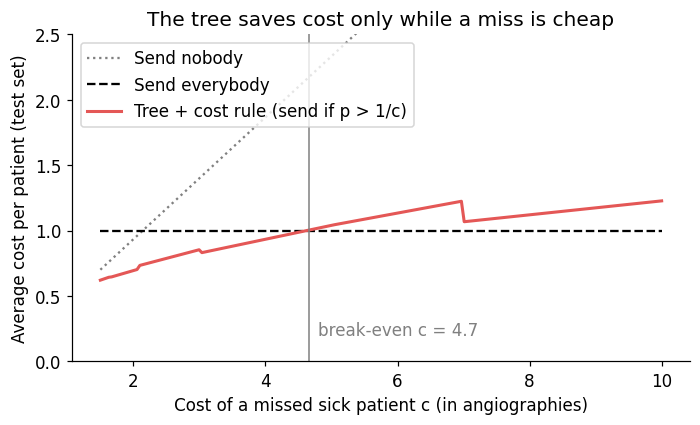

The tree + cost rule is cheaper than 'send everybody' for c below about 4.7.


,c (cost of a miss),threshold 1/c,send nobody,send everybody,tree (cost rule)
0,2,0.50,0.933,1.0,0.693
1,3,0.33,1.400,1.0,0.853
2,4,0.25,1.867,1.0,0.933
3,5,0.20,2.333,1.0,1.040
4,10,0.10,4.667,1.0,1.227


In [18]:
sensitivity = []
for c in [2, 3, 4, 5, 10]:
    t = policy_rows(p_test, y_test, c).set_index("policy")["average cost per patient"]
    sensitivity.append({"c (cost of a miss)": c, "threshold 1/c": round(1 / c, 2),
                        "send nobody": t.iloc[0], "send everybody": t.iloc[1], "tree (cost rule)": t.iloc[3]})
sensitivity = pd.DataFrame(sensitivity)

c_grid = np.linspace(1.5, 10, 200)
tree_curve = [average_cost((p_test > 1 / c).astype(int), y_test, c) for c in c_grid]
break_even = c_grid[np.argmax(np.array(tree_curve) >= 1)]
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(c_grid, c_grid * y_test.mean(), color="grey", ls=":", label="Send nobody")
ax.plot(c_grid, np.ones_like(c_grid), color="black", ls="--", label="Send everybody")
ax.plot(c_grid, tree_curve, color="#E45756", lw=2, label="Tree + cost rule (send if p > 1/c)")
ax.axvline(break_even, color="grey", lw=1)
ax.annotate(f"break-even c = {break_even:.1f}", (break_even, 0.2), xytext=(6, 0), textcoords="offset points", color="grey")
ax.set_ylim(0, 2.5)
ax.set_xlabel("Cost of a missed sick patient c (in angiographies)")
ax.set_ylabel("Average cost per patient (test set)")
ax.set_title("The tree saves cost only while a miss is cheap")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig("figures/06_cost_sensitivity.png")
plt.show()
print(f"The tree + cost rule is cheaper than 'send everybody' for c below about {break_even:.1f}.")
sensitivity

**Why does the tree lose for large $c$?** When $c$ is large, the rule sends almost everyone anyway (threshold $1/c$ is small). The few patients it still leaves out sit in leaves that looked "almost all healthy" in training, but a few of them are sick on the test set. Each such miss costs $c$, so a handful of misses is enough to lose against "send everybody". A model only beats "test everyone" if it is very sure about the patients it leaves out.

## 9. Robustness checks

These checks answer the questions we expect about the method. None of them changes the frozen tree from section 6.

### 9.1 Tuning for the decision cost instead of accuracy

Lecture 3 recommends selecting the model with the loss of the actual decision. We repeat the cross-validation, but score each setting by its **average cost at $c = 3$** (threshold $1/3$) instead of accuracy.

In [19]:
def cost_scorer(c):
    # GridSearchCV maximises the score, so we return minus the average cost.
    def score(estimator, X_val, y_val):
        send = (estimator.predict_proba(X_val)[:, 1] > 1 / c).astype(int)
        return -average_cost(send, y_val, c)
    return score

cost_search = GridSearchCV(DecisionTreeClassifier(random_state=SEED), param_grid, cv=cv, scoring=cost_scorer(3))
cost_search.fit(X_train, y_train)
cost_tree = cost_search.best_estimator_
p_cost = cost_tree.predict_proba(X_test)[:, 1]

tuning_table = pd.DataFrame([
    {"tuned for": "accuracy (section 5)", "max_depth": best_depth, "min_samples_leaf": best_leaf,
     "leaves": tree.get_n_leaves(), "test cost at c=3": average_cost((p_test > 1 / 3).astype(int), y_test, 3),
     "sick missed": int(((p_test <= 1 / 3) & (y_test == 1)).sum())},
    {"tuned for": "cost at c = 3", "max_depth": cost_search.best_params_["max_depth"],
     "min_samples_leaf": cost_search.best_params_["min_samples_leaf"], "leaves": cost_tree.get_n_leaves(),
     "test cost at c=3": average_cost((p_cost > 1 / 3).astype(int), y_test, 3),
     "sick missed": int(((p_cost <= 1 / 3) & (y_test == 1)).sum())},
]).round(3)
tuning_table

,tuned for,max_depth,min_samples_leaf,leaves,test cost at c=3,sick missed
0,accuracy (section 5),4,10,12,0.853,10
1,cost at c = 3,3,1,7,0.880,8


**Reading:** tuning for cost picks a different tree (depth 3, no leaf limit, 7 leaves) instead of depth 4 with at least 10 patients per leaf. On the test set it misses 2 fewer sick patients but sends more healthy ones, and its average cost is almost the same (0.880 vs 0.853, a difference of about 2 patients out of 75). So the tuning criterion changes the tree, but **not the conclusion**. We keep the accuracy-tuned tree as our main model because it was chosen first and has larger, more reliable leaves.

### 9.2 Only information available before any extra test

`n_vessels` (fluoroscopy) and `thal` (thallium scan) are themselves imaging tests, and they are among the most important variables of our tree. If the decision is taken at the consultation, they are not available yet. We rebuild the same tree **without them**, with the same split, the same grid and the same cross-validation.

In [20]:
extra_tests = ["n_vessels"] + [col for col in X.columns if col.startswith("thal_")]
X_train_pre, X_test_pre = X_train.drop(columns=extra_tests), X_test.drop(columns=extra_tests)

pre_search = GridSearchCV(DecisionTreeClassifier(random_state=SEED), param_grid, cv=cv, scoring="accuracy")
pre_search.fit(X_train_pre, y_train)
pre_tree = pre_search.best_estimator_
p_pre = pre_tree.predict_proba(X_test_pre)[:, 1]

timing_table = pd.DataFrame([
    {**scores("All 13 inputs", y_test, y_pred), "depth": tree.get_depth(),
     "test cost at c=3": average_cost((p_test > 1 / 3).astype(int), y_test, 3)},
    {**scores("Without the 2 extra tests", y_test, pre_tree.predict(X_test_pre)), "depth": pre_tree.get_depth(),
     "test cost at c=3": average_cost((p_pre > 1 / 3).astype(int), y_test, 3)},
]).round(3)
print("Root question without the extra tests:", X_train_pre.columns[pre_tree.tree_.feature[0]])
timing_table

Root question without the extra tests: chest_pain_asymptomatic


,model,test accuracy,recall,specificity,depth,test cost at c=3
0,All 13 inputs,0.773,0.686,0.850,4,0.853
1,Without the 2 extra tests,0.747,0.714,0.775,1,0.853


**Reading:** without the two extra tests, cross-validation chooses a single question (asymptomatic chest pain), so this model is exactly the stump of section 7. On our test set it loses about 3 points of accuracy (0.747 vs 0.773), catches slightly more sick patients but leaves out fewer healthy ones, and has the same cost at $c = 3$. A model that uses only consultation and ECG information is therefore **almost as useful**, and it respects the timing of the decision. Section 9.3 checks that this is not luck of one split.

### 9.3 Stability: what if the random split had been different?

Our test set is one random draw of 75 patients. We repeat the **whole procedure** (split, 5-fold tuning, test) for 30 different random splits, for both input sets. Nothing here is used to change the frozen tree; it only shows how much the results move.

In [21]:
def full_run(X_all, seed):
    Xa, Xb, ya, yb = train_test_split(X_all, y, test_size=0.25, stratify=y, random_state=seed)
    folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    fitted = GridSearchCV(DecisionTreeClassifier(random_state=seed), param_grid, cv=folds, scoring="accuracy").fit(Xa, ya)
    best = fitted.best_estimator_
    return {"seed": seed, "test accuracy": accuracy_score(yb, best.predict(Xb)), "cv accuracy": fitted.best_score_,
            "depth": best.get_depth(), "root question": Xa.columns[best.tree_.feature[0]]}

runs_all = pd.DataFrame([full_run(X, seed) for seed in range(30)])
runs_pre = pd.DataFrame([full_run(X.drop(columns=extra_tests), seed) for seed in range(30)])

stability_table = pd.DataFrame([
    {"inputs": name, "mean test accuracy": r["test accuracy"].mean(), "std": r["test accuracy"].std(),
     "min": r["test accuracy"].min(), "max": r["test accuracy"].max(), "mean cv accuracy": r["cv accuracy"].mean(),
     "depths chosen": ", ".join(str(d) for d in sorted(r["depth"].unique()))}
    for name, r in [("All 13 inputs", runs_all), ("Without the 2 extra tests", runs_pre)]
]).round(3)
print("Root question over 30 splits (all inputs):", runs_all["root question"].value_counts().to_dict())
print("Root question over 30 splits (no extra tests):", runs_pre["root question"].value_counts().to_dict())
print(f"Baseline accuracy on every split: {baseline_acc:.3f}. "
      f"Splits where the tree beats it: {(runs_all['test accuracy'] > baseline_acc).sum()}/30 (all inputs), "
      f"{(runs_pre['test accuracy'] > baseline_acc).sum()}/30 (no extra tests)")
stability_table

Root question over 30 splits (all inputs): {'thal_normal': 19, 'chest_pain_asymptomatic': 7, 'n_vessels': 4}
Root question over 30 splits (no extra tests): {'chest_pain_asymptomatic': 30}
Baseline accuracy on every split: 0.533. Splits where the tree beats it: 30/30 (all inputs), 30/30 (no extra tests)


,inputs,mean test accuracy,std,min,max,mean cv accuracy,depths chosen
0,All 13 inputs,0.763,0.047,0.667,0.880,0.784,"1, 2, 3, 4, 5, 7"
1,Without the 2 extra tests,0.729,0.033,0.667,0.787,0.756,"1, 2, 3, 4, 5, 6, 7"


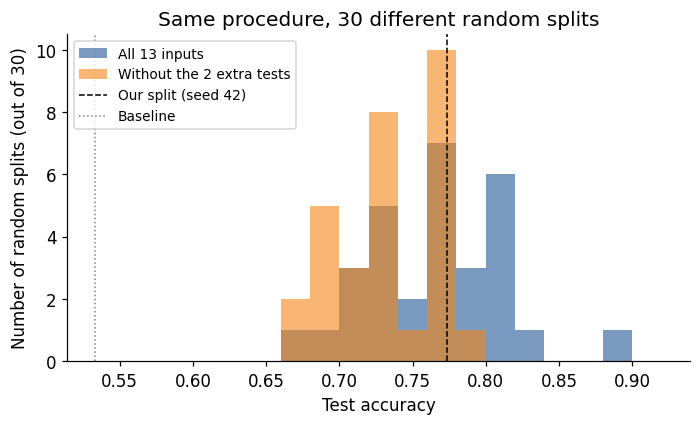

In [22]:
fig, ax = plt.subplots(figsize=(6.5, 4))
bins = np.linspace(0.6, 0.92, 17)
ax.hist(runs_all["test accuracy"], bins=bins, alpha=0.75, color="#4C78A8", label="All 13 inputs")
ax.hist(runs_pre["test accuracy"], bins=bins, alpha=0.6, color="#F58518", label="Without the 2 extra tests")
ax.axvline(accuracy_score(y_test, y_pred), color="black", ls="--", lw=1, label="Our split (seed 42)")
ax.axvline(baseline_acc, color="grey", ls=":", lw=1, label="Baseline")
ax.set_xlabel("Test accuracy")
ax.set_ylabel("Number of random splits (out of 30)")
ax.set_title("Same procedure, 30 different random splits")
ax.legend(loc="upper left", fontsize=9)
fig.tight_layout()
fig.savefig("figures/07_stability.png")
plt.show()

**Reading:**

- Our split (0.773) is a typical draw: the average over 30 splits is 0.763, and the range is about 0.67 to 0.88. The tree beats the baseline (0.533) on **every** split.
- Without the extra tests the average drops to about 0.73, but it is also more stable: smaller spread, and the root question is asymptomatic chest pain on all 30 splits. It still beats the baseline every time.
- The **depth and the root question change from split to split**: the root is `thal_normal`, asymptomatic chest pain or `n_vessels`. These three variables carry the same strong signal, so the tree picks whichever looks best on a given sample. This is the instability of single trees: the overall message is reliable, the exact tree is not.
- The cross-validation score is on average a bit higher than the test score (0.784 vs 0.763): picking the best of 40 settings makes the winning CV score optimistic (Lecture 2).

### 9.4 How precise is one test score of 75 patients?

Lecture 2 gives a bound for a model that is fixed before the test set is used. For a 0–1 loss and $m$ independent test patients, with probability at least $1 - \alpha$:

$$|\text{test error} - \text{true error}| \le \sqrt{\frac{\log(2/\alpha)}{2m}}.$$

In [23]:
m, alpha = len(y_test), 0.05
half_width = np.sqrt(np.log(2 / alpha) / (2 * m))
tree_acc = accuracy_score(y_test, y_pred)
print(f"m = {m}, alpha = {alpha}: half-width = {half_width:.3f}")
print(f"Tree test accuracy {tree_acc:.3f} -> true accuracy between {tree_acc - half_width:.3f} and {min(tree_acc + half_width, 1):.3f} (95%)")

m = 75, alpha = 0.05: half-width = 0.157
Tree test accuracy 0.773 -> true accuracy between 0.617 and 0.930 (95%)


The bound is conservative: it holds for any distribution, so the interval is wide (about ±16 points). It gives the right message: with 75 test patients, differences of a few points between models (for example 0.773 vs 0.747 in section 9.2) are **not meaningful**. The large gap to the baseline is confirmed differently, by section 9.3: the tree beats the baseline on all 30 splits.

## 10. Summary numbers for the slides

In [24]:
tree_cost = policy_table.iloc[3]
summary = {
    "patients used": len(df),
    "share with disease": round(y.mean(), 3),
    "chosen max_depth": best_depth,
    "chosen min_samples_leaf": best_leaf,
    "number of leaves": tree.get_n_leaves(),
    "CV accuracy (training)": round(search.best_score_, 3),
    "baseline test accuracy": round(baseline_acc, 3),
    "tree test accuracy": round(tree_acc, 3),
    "tree test recall (0.5)": round(recall_score(y_test, y_pred), 3),
    "test accuracy 95% half-width (Hoeffding)": round(half_width, 3),
    "cost rule c=3: average cost": tree_cost["average cost per patient"],
    "cost rule c=3: patients sent": tree_cost["patients sent"],
    "cost rule c=3: sick missed": tree_cost["sick patients missed"],
    "break-even c vs send everybody": round(break_even, 1),
    "30 splits: mean test accuracy (all inputs)": round(runs_all["test accuracy"].mean(), 3),
    "30 splits: mean test accuracy (no extra tests)": round(runs_pre["test accuracy"].mean(), 3),
}
pd.Series(summary, name="value").to_frame()

,value
patients used,297.000
share with disease,0.461
chosen max_depth,4.000
chosen min_samples_leaf,10.000
number of leaves,12.000
CV accuracy (training),0.824
baseline test accuracy,0.533
tree test accuracy,0.773
tree test recall (0.5),0.686
test accuracy 95% half-width (Hoeffding),0.157


## 11. Recommendation and limitations

**What the tree is good at.** A depth-4 tree with 12 leaves, readable by a doctor, beats the baseline by about 24 points on the test set. The first question it asks (asymptomatic chest pain) is the strongest single warning sign in this data.

**What it means for the decision.** The best policy depends on how costly a missed sick patient is:

- If a miss costs less than about 4.7 angiographies, the tree with the cost rule (send when $\hat p > 1/c$) is the cheapest policy.
- If a miss costs more, **sending everybody is cheaper and safer**. For a disease that can be fatal, a realistic $c$ is probably in this range.

**Recommendation:** in this data, the tree is **not safe enough to decide alone** who skips angiography. It can be useful as a **triage aid**: to order the waiting list, or to flag high-risk patients first, while the doctor keeps the final decision. Deciding to use it would require the hospital to state its cost $c$ explicitly.

**Limitations**

- **Small, old data:** 297 patients from one hospital, collected in the 1980s, 68% men. Results may not carry over to other populations.
- **Selected patients:** every patient in the data was already sent for angiography (section 1). The tree estimates the risk among patients a doctor already found worrying, not among all patients with chest symptoms.
- **Uncertainty:** with 75 test patients, one patient is about 1.3 accuracy points, and the 95% bound is about ±16 points. Over 30 random splits the test accuracy ranges from about 0.67 to 0.88.
- **Unstable tree:** different splits choose different depths and even different root questions (`thal`, chest pain or `n_vessels`), so the exact tree should not be over-interpreted. The overall performance is stable; the exact questions are not.
- **Timing of information:** `n_vessels` and `thal` come from extra imaging tests. Without them, the tree loses a few points of accuracy (section 9.2) but stays clearly better than the baseline.
- **Costs are assumed:** $c$ is not measured, and the loss table ignores the risk of the angiography itself.
- **Probabilities from leaves are coarse:** each leaf gives one probability for all its patients, and small leaves make these estimates noisy.